In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder , LabelEncoder , MinMaxScaler , StandardScaler, OrdinalEncoder , FunctionTransformer
from sklearn.model_selection import train_test_split , GridSearchCV
from sklearn.ensemble import RandomForestClassifier 
from xgboost import XGBClassifier 
from sklearn.metrics import classification_report , confusion_matrix 
from sklearn.compose import ColumnTransformer 
from sklearn.pipeline import Pipeline 
import pickle as pkl

In [2]:
data = pd.read_csv(r"C:\Users\samsh\Downloads\train (2).xlsx - train (2).csv")
data

,id,perc_premium_paid_by_cash_credit,age_in_days,Income,Count_3-6_months_late,Count_6-12_months_late,Count_more_than_12_months_late,application_underwriting_score,no_of_premiums_paid,sourcing_channel,residence_area_type,premium,renewal
0,66633,0.086,16805,114110,0.0,0.0,0.0,99.87,8,A,Urban,3300,1
1,62807,0.010,22638,315120,0.0,0.0,0.0,99.25,19,A,Rural,3300,1
2,30822,0.312,11685,125100,0.0,0.0,0.0,98.84,13,A,Urban,7500,1
3,101201,0.276,24829,150200,2.0,0.0,0.0,99.02,17,A,Urban,7500,1
4,63479,0.308,20445,137880,0.0,0.0,0.0,98.80,11,A,Rural,7500,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
67870,95125,0.000,14610,105110,0.0,0.0,0.0,99.34,9,A,Urban,5400,1
67871,107201,0.290,16795,30080,0.0,0.0,0.0,96.77,5,A,Urban,1200,1
67872,81642,0.020,11328,93040,0.0,0.0,0.0,99.66,8,B,Urban,11700,1
67873,113183,0.264,25559,166230,0.0,0.0,0.0,99.26,7,B,Urban,9600,1


In [3]:
len(['perc_premium_paid_by_cash_credit', 'age_in_days', 'Income',
       'Count_3-6_months_late', 'Count_6-12_months_late',
       'Count_more_than_12_months_late', 'application_underwriting_score',
       'no_of_premiums_paid', 'sourcing_channel', 'residence_area_type',
       'premium', 'renewal'])

12

In [4]:
data.columns

Index(['id', 'perc_premium_paid_by_cash_credit', 'age_in_days', 'Income',
       'Count_3-6_months_late', 'Count_6-12_months_late',
       'Count_more_than_12_months_late', 'application_underwriting_score',
       'no_of_premiums_paid', 'sourcing_channel', 'residence_area_type',
       'premium', 'renewal'],
      dtype='object')

In [5]:
[0.086,16805,114110,0.0,0.0	,0.0,99.87,8,"A","Urban",3300]

[0.086, 16805, 114110, 0.0, 0.0, 0.0, 99.87, 8, 'A', 'Urban', 3300]

In [6]:
data.duplicated().sum()

np.int64(0)

In [7]:
data.isnull().sum()

id                                     0
perc_premium_paid_by_cash_credit       0
age_in_days                            0
Income                                 0
Count_3-6_months_late                 88
Count_6-12_months_late                88
Count_more_than_12_months_late        88
application_underwriting_score      2539
no_of_premiums_paid                    0
sourcing_channel                       0
residence_area_type                    0
premium                                0
renewal                                0
dtype: int64

In [8]:
data[data['Count_3-6_months_late'].isna() == True ] [data[data['Count_6-12_months_late'].isna() == True]['renewal'] == 0]

,id,perc_premium_paid_by_cash_credit,age_in_days,Income,Count_3-6_months_late,Count_6-12_months_late,Count_more_than_12_months_late,application_underwriting_score,no_of_premiums_paid,sourcing_channel,residence_area_type,premium,renewal
6849,78128,1.0,13155,98400,NaN,NaN,NaN,99.88,2,C,Urban,5400,0
8489,69950,1.0,23005,29640,NaN,NaN,NaN,NaN,2,A,Urban,3300,0
8618,50034,1.0,21185,75130,NaN,NaN,NaN,NaN,2,A,Urban,5700,0
9804,102893,1.0,12416,105040,NaN,NaN,NaN,NaN,2,B,Urban,7500,0
10403,66964,1.0,21545,65530,NaN,NaN,NaN,NaN,2,A,Rural,1200,0
13309,10830,1.0,12060,100620,NaN,NaN,NaN,NaN,2,B,Rural,5400,0
17737,68994,1.0,16065,188630,NaN,NaN,NaN,NaN,3,C,Urban,13800,0
18054,41527,1.0,28849,33810,NaN,NaN,NaN,99.89,2,A,Rural,1200,0
20887,50356,1.0,16431,108030,NaN,NaN,NaN,NaN,2,A,Urban,7500,0
21429,42642,1.0,16072,87530,NaN,NaN,NaN,99.81,2,C,Urban,5400,0


In [9]:
X = data.drop(columns = ['id' , 'renewal'])
y = data['renewal']

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X,y , test_size = 0.2 , random_state = 42 , stratify = y)

### Impute null value in the columns

In [11]:
si = SimpleImputer(strategy = "median")

In [12]:
data = X_train

In [13]:
data['renewal'] = y_train

In [14]:
data

,perc_premium_paid_by_cash_credit,age_in_days,Income,Count_3-6_months_late,Count_6-12_months_late,Count_more_than_12_months_late,application_underwriting_score,no_of_premiums_paid,sourcing_channel,residence_area_type,premium,renewal
33431,0.957,13877,137720,0.0,0.0,0.0,98.05,14,A,Rural,9600,0
31264,0.046,22270,328970,0.0,0.0,0.0,99.30,17,A,Rural,24300,1
63668,0.630,12789,180120,0.0,0.0,0.0,97.92,18,B,Urban,20100,1
47943,0.198,16065,186040,0.0,0.0,0.0,99.13,13,D,Rural,9600,1
9653,0.021,25562,89520,1.0,0.0,0.0,99.60,8,A,Rural,3300,0
...,...,...,...,...,...,...,...,...,...,...,...,...
59827,0.558,16068,82190,0.0,0.0,0.0,99.23,8,C,Rural,3300,1
5974,1.000,15709,242520,0.0,1.0,0.0,NaN,3,B,Rural,11700,1
8206,0.363,22270,165050,0.0,0.0,0.0,99.60,7,A,Urban,13800,1
59915,0.115,19352,90520,0.0,0.0,0.0,98.79,18,A,Urban,5400,1


In [15]:
num_data = data.select_dtypes(include = "number")

In [16]:
num_data.drop(columns = "renewal").columns

Index(['perc_premium_paid_by_cash_credit', 'age_in_days', 'Income',
       'Count_3-6_months_late', 'Count_6-12_months_late',
       'Count_more_than_12_months_late', 'application_underwriting_score',
       'no_of_premiums_paid', 'premium'],
      dtype='object')

In [17]:
X = data[['perc_premium_paid_by_cash_credit', 'age_in_days', 'Income',
       'Count_3-6_months_late', 'Count_6-12_months_late',
       'Count_more_than_12_months_late', 'application_underwriting_score',
       'no_of_premiums_paid', 'premium']]

In [18]:
y = si.fit_transform(X)

In [19]:
data[['perc_premium_paid_by_cash_credit', 'age_in_days', 'Income',
       'Count_3-6_months_late', 'Count_6-12_months_late',
       'Count_more_than_12_months_late', 'application_underwriting_score',
       'no_of_premiums_paid', 'premium']] = y

In [20]:
data.isna().sum()

perc_premium_paid_by_cash_credit    0
age_in_days                         0
Income                              0
Count_3-6_months_late               0
Count_6-12_months_late              0
Count_more_than_12_months_late      0
application_underwriting_score      0
no_of_premiums_paid                 0
sourcing_channel                    0
residence_area_type                 0
premium                             0
renewal                             0
dtype: int64

### LabelEncoding --> in residence_area_type

In [21]:
le = LabelEncoder()

In [22]:
X = data['residence_area_type']

In [23]:
data['encoded_residence_area_type'] = le.fit_transform(X)

#### OneHotEncoder --> in source channel 

In [24]:
OHE = OneHotEncoder(sparse_output= False , handle_unknown= "ignore")

In [25]:
X = data[['sourcing_channel']]

In [26]:
data['sourcing_channel'].unique()

array(['A', 'B', 'D', 'C', 'E'], dtype=object)

In [27]:
data[['A', 'B', 'C', 'D', 'E']] = OHE.fit_transform(X)

In [28]:
OHE.fit_transform(X)

array([[1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0.]], shape=(54300, 5))

In [29]:
data

,perc_premium_paid_by_cash_credit,age_in_days,Income,Count_3-6_months_late,Count_6-12_months_late,Count_more_than_12_months_late,application_underwriting_score,no_of_premiums_paid,sourcing_channel,residence_area_type,premium,renewal,encoded_residence_area_type,A,B,C,D,E
33431,0.957,13877.0,137720.0,0.0,0.0,0.0,98.05,14.0,A,Rural,9600.0,0,0,1.0,0.0,0.0,0.0,0.0
31264,0.046,22270.0,328970.0,0.0,0.0,0.0,99.30,17.0,A,Rural,24300.0,1,0,1.0,0.0,0.0,0.0,0.0
63668,0.630,12789.0,180120.0,0.0,0.0,0.0,97.92,18.0,B,Urban,20100.0,1,1,0.0,1.0,0.0,0.0,0.0
47943,0.198,16065.0,186040.0,0.0,0.0,0.0,99.13,13.0,D,Rural,9600.0,1,0,0.0,0.0,0.0,1.0,0.0
9653,0.021,25562.0,89520.0,1.0,0.0,0.0,99.60,8.0,A,Rural,3300.0,0,0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59827,0.558,16068.0,82190.0,0.0,0.0,0.0,99.23,8.0,C,Rural,3300.0,1,0,0.0,0.0,1.0,0.0,0.0
5974,1.000,15709.0,242520.0,0.0,1.0,0.0,99.21,3.0,B,Rural,11700.0,1,0,0.0,1.0,0.0,0.0,0.0
8206,0.363,22270.0,165050.0,0.0,0.0,0.0,99.60,7.0,A,Urban,13800.0,1,1,1.0,0.0,0.0,0.0,0.0
59915,0.115,19352.0,90520.0,0.0,0.0,0.0,98.79,18.0,A,Urban,5400.0,1,1,1.0,0.0,0.0,0.0,0.0


#### Incoded_Data

In [30]:
encoded_data = data.drop(columns = ['sourcing_channel',"residence_area_type"])

In [31]:
encoded_data

,perc_premium_paid_by_cash_credit,age_in_days,Income,Count_3-6_months_late,Count_6-12_months_late,Count_more_than_12_months_late,application_underwriting_score,no_of_premiums_paid,premium,renewal,encoded_residence_area_type,A,B,C,D,E
33431,0.957,13877.0,137720.0,0.0,0.0,0.0,98.05,14.0,9600.0,0,0,1.0,0.0,0.0,0.0,0.0
31264,0.046,22270.0,328970.0,0.0,0.0,0.0,99.30,17.0,24300.0,1,0,1.0,0.0,0.0,0.0,0.0
63668,0.630,12789.0,180120.0,0.0,0.0,0.0,97.92,18.0,20100.0,1,1,0.0,1.0,0.0,0.0,0.0
47943,0.198,16065.0,186040.0,0.0,0.0,0.0,99.13,13.0,9600.0,1,0,0.0,0.0,0.0,1.0,0.0
9653,0.021,25562.0,89520.0,1.0,0.0,0.0,99.60,8.0,3300.0,0,0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59827,0.558,16068.0,82190.0,0.0,0.0,0.0,99.23,8.0,3300.0,1,0,0.0,0.0,1.0,0.0,0.0
5974,1.000,15709.0,242520.0,0.0,1.0,0.0,99.21,3.0,11700.0,1,0,0.0,1.0,0.0,0.0,0.0
8206,0.363,22270.0,165050.0,0.0,0.0,0.0,99.60,7.0,13800.0,1,1,1.0,0.0,0.0,0.0,0.0
59915,0.115,19352.0,90520.0,0.0,0.0,0.0,98.79,18.0,5400.0,1,1,1.0,0.0,0.0,0.0,0.0


### check corelation between all columns 

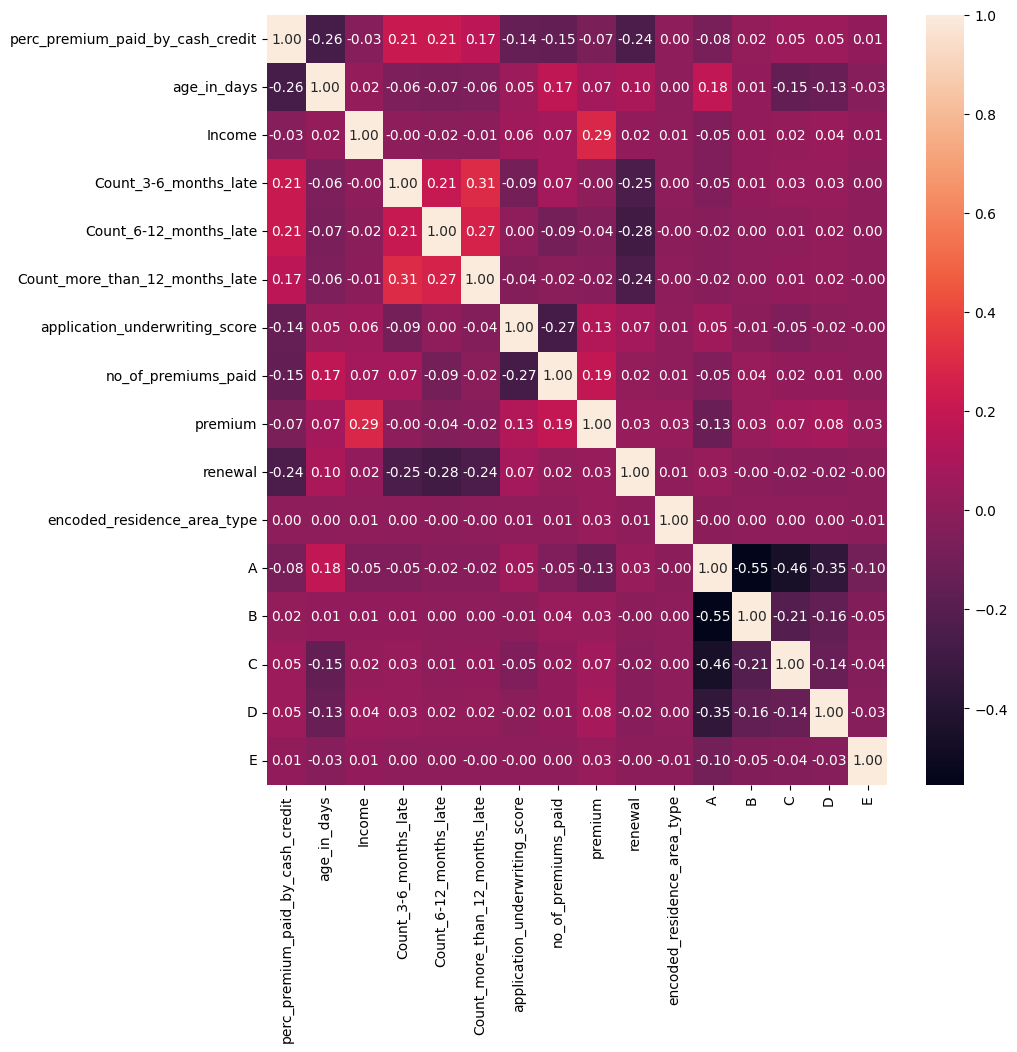

In [32]:
plt.figure(figsize = (10,10))
sns.heatmap(encoded_data.corr() , annot = True , fmt = ".2f")
plt.show()

<Axes: xlabel='Count_3-6_months_late', ylabel='renewal'>

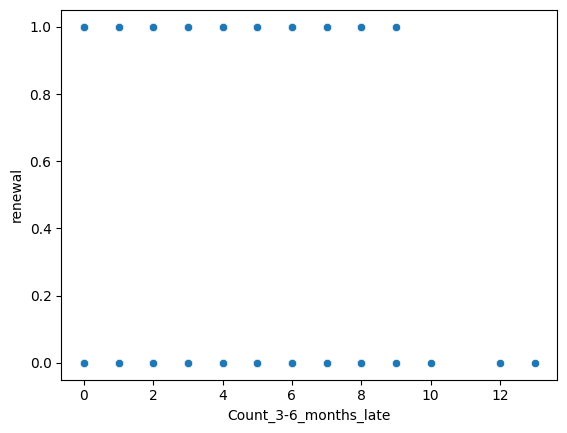

In [33]:
sns.scatterplot(x  = encoded_data['Count_3-6_months_late'] ,y =  encoded_data["renewal"])

<Axes: xlabel='Count_6-12_months_late', ylabel='renewal'>

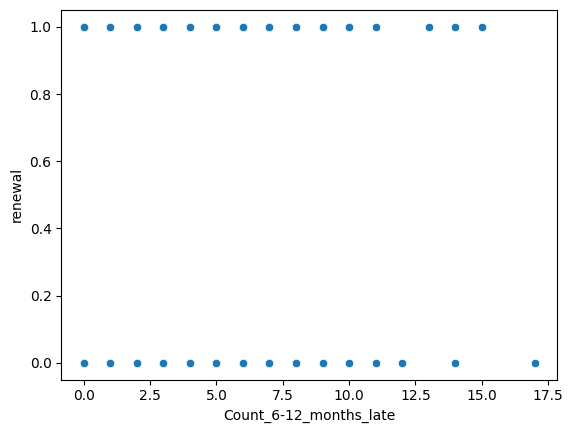

In [34]:
sns.scatterplot(x = encoded_data['Count_6-12_months_late'],y=encoded_data["renewal"])

In [35]:
encoded_data.columns

Index(['perc_premium_paid_by_cash_credit', 'age_in_days', 'Income',
       'Count_3-6_months_late', 'Count_6-12_months_late',
       'Count_more_than_12_months_late', 'application_underwriting_score',
       'no_of_premiums_paid', 'premium', 'renewal',
       'encoded_residence_area_type', 'A', 'B', 'C', 'D', 'E'],
      dtype='object')

<Axes: xlabel='Count_more_than_12_months_late', ylabel='renewal'>

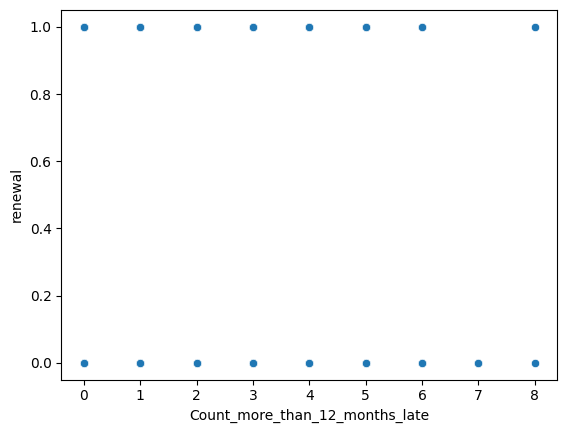

In [36]:
sns.scatterplot(x= encoded_data['Count_more_than_12_months_late'],y=encoded_data["renewal"])

In [37]:
encoded_data["Total_Late"] = encoded_data['Count_3-6_months_late'] + encoded_data['Count_more_than_12_months_late'] + encoded_data['Count_6-12_months_late']

In [38]:
encoded_data.drop(columns = ['Count_3-6_months_late', 'Count_more_than_12_months_late', 'Count_6-12_months_late'], inplace = True)

In [39]:
encoded_data['renewal'].value_counts()

renewal
1    50902
0     3398
Name: count, dtype: int64

### Oversampling (SMOTE)

In [40]:
# pip install  imbalanced-learn

In [41]:
from imblearn.over_sampling import SMOTENC

In [42]:
X = encoded_data.drop(columns = 'renewal')

In [43]:
y = encoded_data[['renewal']]

In [44]:
smt = SMOTENC(categorical_features = [7,8,9,10,11,12], random_state=42)

In [45]:
x,y = smt.fit_resample(X,y)

In [46]:
x,y

(        perc_premium_paid_by_cash_credit   age_in_days         Income  \
 0                               0.957000  13877.000000  137720.000000   
 1                               0.046000  22270.000000  328970.000000   
 2                               0.630000  12789.000000  180120.000000   
 3                               0.198000  16065.000000  186040.000000   
 4                               0.021000  25562.000000   89520.000000   
 ...                                  ...           ...            ...   
 101799                          0.907292  22755.555176  136279.303523   
 101800                          0.714416  19437.787007   43446.504372   
 101801                          0.264661  22853.269231  156353.361979   
 101802                          0.649865  11544.254360  111862.654843   
 101803                          0.585735  14974.662047  112873.795301   
 
         application_underwriting_score  no_of_premiums_paid       premium  \
 0                            98

In [47]:
new_data = x

In [48]:
new_data['renewal'] = y['renewal']

In [49]:
new_data

,perc_premium_paid_by_cash_credit,age_in_days,Income,application_underwriting_score,no_of_premiums_paid,premium,encoded_residence_area_type,A,B,C,D,E,Total_Late,renewal
0,0.957000,13877.000000,137720.000000,98.050000,14.000000,9600.000000,0,1.0,0.0,0.0,0.0,0.0,0.0,0
1,0.046000,22270.000000,328970.000000,99.300000,17.000000,24300.000000,0,1.0,0.0,0.0,0.0,0.0,0.0,1
2,0.630000,12789.000000,180120.000000,97.920000,18.000000,20100.000000,1,0.0,1.0,0.0,0.0,0.0,0.0,1
3,0.198000,16065.000000,186040.000000,99.130000,13.000000,9600.000000,0,0.0,0.0,0.0,1.0,0.0,0.0,1
4,0.021000,25562.000000,89520.000000,99.600000,8.000000,3300.000000,0,1.0,0.0,0.0,0.0,0.0,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101799,0.907292,22755.555176,136279.303523,98.400139,9.597217,1200.000000,0,1.0,0.0,0.0,0.0,0.0,3.0,0
101800,0.714416,19437.787007,43446.504372,98.954084,10.616672,3300.000000,0,1.0,0.0,0.0,0.0,0.0,2.0,0
101801,0.264661,22853.269231,156353.361979,98.505827,8.500081,15024.971624,1,0.0,0.0,0.0,0.0,0.0,0.0,0
101802,0.649865,11544.254360,111862.654843,98.493555,9.899192,9600.000000,0,0.0,0.0,0.0,0.0,0.0,0.0,0


### Scalling 

In [50]:
sd = StandardScaler()

In [51]:
scaled_x = sd.fit_transform(new_data[['perc_premium_paid_by_cash_credit', 'age_in_days', 'Income',
       'application_underwriting_score', 'no_of_premiums_paid', 'premium', 'Total_Late']])

In [52]:
scaled_x

array([[ 1.40702608, -0.82139211, -0.13909846, ...,  0.64096761,
        -0.07792217, -0.50827804],
       [-1.17894141,  0.8685984 ,  0.33215726, ...,  1.22670375,
         1.56299467, -0.50827804],
       [ 0.47880284, -1.04046868, -0.03462138, ...,  1.42194913,
         1.09416129, -0.50827804],
       ...,
       [-0.55824901,  0.98604382, -0.09318433, ..., -0.43286616,
         0.52765111, -0.50827804],
       [ 0.5351927 , -1.2911071 , -0.20281309, ..., -0.15969619,
        -0.07792217, -0.50827804],
       [ 0.35315147, -0.60037001, -0.20032155, ..., -0.62948032,
        -0.68376936, -0.50827804]], shape=(101804, 7))

In [53]:
new_data[['perc_premium_paid_by_cash_credit', 'age_in_days', 'Income',
       'application_underwriting_score', 'no_of_premiums_paid', 'premium', 'Total_Late']] = scaled_x

In [54]:
new_data 

,perc_premium_paid_by_cash_credit,age_in_days,Income,application_underwriting_score,no_of_premiums_paid,premium,encoded_residence_area_type,A,B,C,D,E,Total_Late,renewal
0,1.407026,-0.821392,-0.139098,-1.275349,0.640968,-0.077922,0,1.0,0.0,0.0,0.0,0.0,-0.508278,0
1,-1.178941,0.868598,0.332157,0.439403,1.226704,1.562995,0,1.0,0.0,0.0,0.0,0.0,-0.508278,1
2,0.478803,-1.040469,-0.034621,-1.453683,1.421949,1.094161,1,0.0,1.0,0.0,0.0,0.0,-0.508278,1
3,-0.747474,-0.380823,-0.020034,0.206196,0.445722,-0.077922,0,0.0,0.0,0.0,1.0,0.0,-0.508278,1
4,-1.249906,1.531466,-0.257867,0.850943,-0.530505,-0.781172,0,1.0,0.0,0.0,0.0,0.0,0.202882,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101799,1.265925,0.966368,-0.142648,-0.795028,-0.218655,-1.015589,0,1.0,0.0,0.0,0.0,0.0,1.625203,0
101800,0.718425,0.298312,-0.371396,-0.035125,-0.019612,-0.781172,0,1.0,0.0,0.0,0.0,0.0,0.914043,0
101801,-0.558249,0.986044,-0.093184,-0.650045,-0.432866,0.527651,1,0.0,0.0,0.0,0.0,0.0,-0.508278,0
101802,0.535193,-1.291107,-0.202813,-0.666879,-0.159696,-0.077922,0,0.0,0.0,0.0,0.0,0.0,-0.508278,0


### now we can use any algorithm for training data.. 

In [55]:
# RandomForest , XGB

In [56]:
X = new_data[["perc_premium_paid_by_cash_credit","age_in_days","Income","application_underwriting_score","no_of_premiums_paid","premium","encoded_residence_area_type","A","B","C","D","E","Total_Late"]]

In [57]:
y = new_data['renewal']

In [58]:
rf = RandomForestClassifier()

In [59]:
rf.fit(X,y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [60]:
X_TEST = X_test.drop(columns = ["sourcing_channel","residence_area_type"])

In [61]:
X_TEST.columns

Index(['perc_premium_paid_by_cash_credit', 'age_in_days', 'Income',
       'Count_3-6_months_late', 'Count_6-12_months_late',
       'Count_more_than_12_months_late', 'application_underwriting_score',
       'no_of_premiums_paid', 'premium'],
      dtype='object')

In [62]:
X_TEST[['perc_premium_paid_by_cash_credit', 'age_in_days', 'Income',
       'Count_3-6_months_late', 'Count_6-12_months_late',
       'Count_more_than_12_months_late', 'application_underwriting_score',
       'no_of_premiums_paid', 'premium']] = si.transform(X_TEST)

In [63]:
X_TEST['renewal'] = y_test

In [64]:
X_TEST[["sourcing_channel","residence_area_type"]] = X_test[["sourcing_channel","residence_area_type"]]

In [65]:
X_TEST

,perc_premium_paid_by_cash_credit,age_in_days,Income,Count_3-6_months_late,Count_6-12_months_late,Count_more_than_12_months_late,application_underwriting_score,no_of_premiums_paid,premium,renewal,sourcing_channel,residence_area_type
65195,0.077,21907.0,105100.0,0.0,0.0,0.0,98.23,15.0,7500.0,1,A,Urban
52964,0.159,18624.0,270310.0,0.0,0.0,0.0,99.26,10.0,3300.0,1,B,Rural
27957,0.603,12790.0,120100.0,0.0,0.0,0.0,99.67,5.0,5400.0,1,A,Urban
31263,0.130,15708.0,129650.0,0.0,0.0,0.0,98.78,10.0,7500.0,1,B,Urban
49280,0.659,21912.0,255100.0,3.0,0.0,0.0,98.40,22.0,18000.0,1,A,Rural
...,...,...,...,...,...,...,...,...,...,...,...,...
9118,0.547,17525.0,150070.0,0.0,0.0,0.0,98.70,9.0,11700.0,1,C,Urban
1602,0.084,17170.0,189060.0,0.0,0.0,0.0,99.13,11.0,9600.0,1,B,Urban
30642,0.015,21906.0,150110.0,0.0,0.0,0.0,99.81,14.0,9600.0,1,A,Urban
24352,1.000,10955.0,39040.0,0.0,0.0,1.0,99.72,5.0,5700.0,0,A,Rural


In [66]:
X_TEST["encoded_residence_area_type"] = le.transform(X_TEST["residence_area_type"])

In [67]:
X_TEST[['A', 'B', 'C', 'D', 'E']] = OHE.transform(X_TEST[["sourcing_channel"]])

In [68]:
X_TEST

,perc_premium_paid_by_cash_credit,age_in_days,Income,Count_3-6_months_late,Count_6-12_months_late,Count_more_than_12_months_late,application_underwriting_score,no_of_premiums_paid,premium,renewal,sourcing_channel,residence_area_type,encoded_residence_area_type,A,B,C,D,E
65195,0.077,21907.0,105100.0,0.0,0.0,0.0,98.23,15.0,7500.0,1,A,Urban,1,1.0,0.0,0.0,0.0,0.0
52964,0.159,18624.0,270310.0,0.0,0.0,0.0,99.26,10.0,3300.0,1,B,Rural,0,0.0,1.0,0.0,0.0,0.0
27957,0.603,12790.0,120100.0,0.0,0.0,0.0,99.67,5.0,5400.0,1,A,Urban,1,1.0,0.0,0.0,0.0,0.0
31263,0.130,15708.0,129650.0,0.0,0.0,0.0,98.78,10.0,7500.0,1,B,Urban,1,0.0,1.0,0.0,0.0,0.0
49280,0.659,21912.0,255100.0,3.0,0.0,0.0,98.40,22.0,18000.0,1,A,Rural,0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9118,0.547,17525.0,150070.0,0.0,0.0,0.0,98.70,9.0,11700.0,1,C,Urban,1,0.0,0.0,1.0,0.0,0.0
1602,0.084,17170.0,189060.0,0.0,0.0,0.0,99.13,11.0,9600.0,1,B,Urban,1,0.0,1.0,0.0,0.0,0.0
30642,0.015,21906.0,150110.0,0.0,0.0,0.0,99.81,14.0,9600.0,1,A,Urban,1,1.0,0.0,0.0,0.0,0.0
24352,1.000,10955.0,39040.0,0.0,0.0,1.0,99.72,5.0,5700.0,0,A,Rural,0,1.0,0.0,0.0,0.0,0.0


In [69]:
X_TEST['Total_Late'] =  X_TEST['Count_3-6_months_late'] +  X_TEST['Count_6-12_months_late'] + X_TEST['Count_more_than_12_months_late']

In [70]:
X_TEST

,perc_premium_paid_by_cash_credit,age_in_days,Income,Count_3-6_months_late,Count_6-12_months_late,Count_more_than_12_months_late,application_underwriting_score,no_of_premiums_paid,premium,renewal,sourcing_channel,residence_area_type,encoded_residence_area_type,A,B,C,D,E,Total_Late
65195,0.077,21907.0,105100.0,0.0,0.0,0.0,98.23,15.0,7500.0,1,A,Urban,1,1.0,0.0,0.0,0.0,0.0,0.0
52964,0.159,18624.0,270310.0,0.0,0.0,0.0,99.26,10.0,3300.0,1,B,Rural,0,0.0,1.0,0.0,0.0,0.0,0.0
27957,0.603,12790.0,120100.0,0.0,0.0,0.0,99.67,5.0,5400.0,1,A,Urban,1,1.0,0.0,0.0,0.0,0.0,0.0
31263,0.130,15708.0,129650.0,0.0,0.0,0.0,98.78,10.0,7500.0,1,B,Urban,1,0.0,1.0,0.0,0.0,0.0,0.0
49280,0.659,21912.0,255100.0,3.0,0.0,0.0,98.40,22.0,18000.0,1,A,Rural,0,1.0,0.0,0.0,0.0,0.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9118,0.547,17525.0,150070.0,0.0,0.0,0.0,98.70,9.0,11700.0,1,C,Urban,1,0.0,0.0,1.0,0.0,0.0,0.0
1602,0.084,17170.0,189060.0,0.0,0.0,0.0,99.13,11.0,9600.0,1,B,Urban,1,0.0,1.0,0.0,0.0,0.0,0.0
30642,0.015,21906.0,150110.0,0.0,0.0,0.0,99.81,14.0,9600.0,1,A,Urban,1,1.0,0.0,0.0,0.0,0.0,0.0
24352,1.000,10955.0,39040.0,0.0,0.0,1.0,99.72,5.0,5700.0,0,A,Rural,0,1.0,0.0,0.0,0.0,0.0,1.0


In [71]:
scaled_x = sd.transform(X_TEST[['perc_premium_paid_by_cash_credit', 'age_in_days', 'Income',
       'application_underwriting_score', 'no_of_premiums_paid', 'premium', 'Total_Late']])

In [72]:
X_TEST[['perc_premium_paid_by_cash_credit', 'age_in_days', 'Income',
       'application_underwriting_score', 'no_of_premiums_paid', 'premium', 'Total_Late']] =  scaled_x

In [73]:
X_TEST.drop(columns = ["Count_3-6_months_late","Count_6-12_months_late","Count_more_than_12_months_late", "sourcing_channel","residence_area_type"], inplace = True)

In [74]:
y_test = X_TEST['renewal']

In [75]:
X_test = X_TEST[["perc_premium_paid_by_cash_credit","age_in_days","Income","application_underwriting_score","no_of_premiums_paid","premium","encoded_residence_area_type","A","B","C","D","E","Total_Late"]]

In [76]:
y_pred = rf.predict(X_test)

In [77]:
print(classification_report(y_test , y_pred))

              precision    recall  f1-score   support

           0       0.22      0.33      0.26       850
           1       0.95      0.92      0.94     12725

    accuracy                           0.88     13575
   macro avg       0.59      0.63      0.60     13575
weighted avg       0.91      0.88      0.89     13575



In [78]:
#si , OHE, Label encode, total late, scaling

In [79]:
X_TEST['renewal'].value_counts()

renewal
1    12725
0      850
Name: count, dtype: int64

In [80]:
confusion_matrix(y_test , y_pred)

array([[  280,   570],
       [ 1005, 11720]])

In [81]:
xgb = XGBClassifier(n_estimators = 100 , max_depth = 5 , n_jobs = -1)

In [82]:
xgb.fit(X,y)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [83]:
y_predict = xgb.predict(X_test)

In [84]:
print(classification_report(y_test ,y_predict))

              precision    recall  f1-score   support

           0       0.46      0.19      0.27       850
           1       0.95      0.99      0.97     12725

    accuracy                           0.94     13575
   macro avg       0.71      0.59      0.62     13575
weighted avg       0.92      0.94      0.92     13575



In [85]:
grid_param = {
    "n_estimators": [100 , 50 ,55 , 150 , 10 , 200 , 250 , 300],
    "max_depth" : [1,3,5,7,9]
}

In [86]:
gd = GridSearchCV(
    estimator = xgb ,
    param_grid = grid_param ,
    cv = 5 , 
    n_jobs = -1 ,
    scoring = "recall"
)

In [87]:
gd.fit(X,y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [1, 3, ...], 'n_estimators': [100, 50, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informat

In [88]:
gd.best_params_

{'max_depth': 3, 'n_estimators': 300}

In [89]:
new_xgb = gd.best_estimator_

In [90]:
new_y = new_xgb.predict(X_test)

In [91]:
print(classification_report(y_test , new_y))

              precision    recall  f1-score   support

           0       0.45      0.16      0.24       850
           1       0.95      0.99      0.97     12725

    accuracy                           0.94     13575
   macro avg       0.70      0.57      0.60     13575
weighted avg       0.92      0.94      0.92     13575



In [92]:
sample_data = pd.read_csv(r"C:\Users\samsh\Downloads\train (2).xlsx - train (2).csv")

In [93]:
sample_data.columns

Index(['id', 'perc_premium_paid_by_cash_credit', 'age_in_days', 'Income',
       'Count_3-6_months_late', 'Count_6-12_months_late',
       'Count_more_than_12_months_late', 'application_underwriting_score',
       'no_of_premiums_paid', 'sourcing_channel', 'residence_area_type',
       'premium', 'renewal'],
      dtype='object')

### New build same things but with the pipelines. 



In [94]:
# def create_total_late(a):
#     a=a.copy()
#     a["Total_late"] = a['Count_3-6_months_late'] + a['Count_6-12_months_late'] +a['Count_more_than_12_months_late']
#     a.drop(columns = ['Count_3-6_months_late','Count_6-12_months_late','Count_more_than_12_months_late'], inplace =True)
#     return a

In [95]:
from custom_function import create_total_late

In [96]:
simple_impute = ColumnTransformer(
    transformers = [
        ("median_imputer", SimpleImputer(strategy="median"),['perc_premium_paid_by_cash_credit', 'age_in_days', 'Income',
       'Count_3-6_months_late', 'Count_6-12_months_late',
       'Count_more_than_12_months_late', 'application_underwriting_score',
       'no_of_premiums_paid',
       'premium']),
        ("cat_imputer",SimpleImputer(strategy="most_frequent"),['sourcing_channel', 'residence_area_type',])
    ],
    verbose_feature_names_out=False
)

In [97]:
prepared_data = ColumnTransformer(
    transformers = [
        ("Standard_scaling", StandardScaler(),['perc_premium_paid_by_cash_credit', 'age_in_days', 'Income', 'application_underwriting_score',
       'no_of_premiums_paid',
       'premium']),
        ("OHE_encoding", OneHotEncoder(sparse_output=False, handle_unknown='ignore'),['sourcing_channel']),
        ("ordinal_encoding",OrdinalEncoder(),['residence_area_type']),
        ("total_late", FunctionTransformer(create_total_late), ["Count_3-6_months_late","Count_6-12_months_late","Count_more_than_12_months_late"]),
    ]
)

In [98]:
final = Pipeline([
    ("imputation",simple_impute.set_output(transform="pandas")),
    ("data_prep", prepared_data),
    ("model", XGBClassifier(max_depth= 5, n_estimators= 200))
])

In [99]:
X_train, X_test, y_train, y_test = train_test_split(sample_data.drop(columns = ["id","renewal"]), sample_data["renewal"], test_size = 0.2, stratify = sample_data["renewal"], random_state = 42)


In [100]:
final.fit(X_train , y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputation', ...), ('data_prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['perc_premium_paid_by_cash_credit','age_in_days','Income',..., 'sourcing_channel','residence_area_type','premium']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('median_imputer', ...), ('cat_imputer', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the t

In [101]:
y_pred = final.predict(X_test)

In [102]:
print(classification_report(y_test , y_pred))

              precision    recall  f1-score   support

           0       0.48      0.14      0.22       850
           1       0.95      0.99      0.97     12725

    accuracy                           0.94     13575
   macro avg       0.71      0.57      0.59     13575
weighted avg       0.92      0.94      0.92     13575



In [103]:
### save model 

In [104]:
with open(r"C:\Users\samsh\Desktop\decode_ML\Insurance_project\insurance_project.pkl","wb") as f:
    pkl.dump( obj = final, file = f)